# S1â€“S3: Exact References, MPS, and Pauli Backpropagation

An executable experiment notebook for the three **public** BlueQubit OTOC samples.
It uses **Qiskit Aer** for exact numerical references, **quimb CircuitMPS** for MPS,
and **Qiskit operator backpropagation (OBP)** for Pauli propagation.

**Official answers are not bundled.** The data-status cell below reports the
local QASM/ZIP inputs. Official execution is **disabled by default**; this saved
notebook validates only small synthetic circuits with at most four qubits.
Synthetic correctness checks are explicitly
separated from S1/S2/S3 measurements and are never exported as official answers.

The notebook and the batch CLI import the same modules in `src/bluequbit_samples/`.
No BlueQubit token, paid API call, or scheduler submission is needed to run it.

## Goal

For every independent per-qubit program, compute

$$F_{c,q}=\langle0^{n_c}|U_{c,q}^{\dagger}Z_qU_{c,q}|0^{n_c}\rangle.$$

Here $c\in\{S1,S2,S3\}$ identifies a sample, $q$ is the target qubit, $n_c$ is
the QASM register size, and $U_{c,q}$ is **that ID's program**. Running one file
and measuring all its qubits does not replace the other per-ID files.

The physical range is $[-1,1]$. In Qiskit's Pauli label, q0 is on the **right**:
`"I" * (n - 1 - q) + "Z" + "I" * q`.

The saved results distinguish `EXACT_COMPUTED` from `EXACT_CROSSCHECKED` references.
Neither label means that the organizers disclosed a ground-truth file.

## Setup

Use the isolated Python **3.11.5 or later in the 3.11 series** environment from
`README_samples.md`. The checked dependency versions are in `requirements.lock`.
Select the **Python 3.11 (BlueQubit samples)** kernel. Do not install these packages
into an environment used by ongoing research jobs.

The settings below are the only user-edited experiment controls. `RUN_OFFICIAL`
enables local QASM computations only when explicitly set to `True` and the
complete input manifest is valid. Leave it `False` for small-scale validation.
All tasks use CPU, one worker at a time, with bounded memory and wall time.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "bluequbit_samples").is_dir():
    raise RuntimeError("Open this notebook from the DuQuantum project root.")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("NUMBA_NUM_THREADS", "2")

DATA_ROOT = Path(os.environ.get("BLUEQUBIT_SAMPLE_DATA", ROOT / "problems"))
OUTPUT_ROOT = Path(os.environ.get("BLUEQUBIT_SAMPLE_OUTPUT", ROOT / "results" / "samples_notebook"))
PROFILE = os.environ.get("BLUEQUBIT_SAMPLE_PROFILE", "local")
RUN_OFFICIAL = False
RUN_SYNTHETIC_CHECKS = True
RUN_SMALL_PIPELINE = True
CHIS = (16, 32, 64, 128, 256)
ETAS = (1e-2, 1e-3, 1e-4, 1e-5)

In [2]:
import json
import pandas as pd
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
from bluequbit_samples.models import RunConfig
from bluequbit_samples.provenance import package_versions, atomic_json, environment_receipt
from bluequbit_samples.inputs import discover_samples
from bluequbit_samples.experiment import run_suite
from bluequbit_samples.analysis import (
    records_frame, comparison_table, summary_table, export_results, verify_exports,
)

profile_path = ROOT / "profiles" / f"{PROFILE}.json"
config = RunConfig(**json.loads(profile_path.read_text(encoding="utf-8")))
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
atomic_json(OUTPUT_ROOT / "notebook_environment.json", environment_receipt(config))
display(pd.DataFrame(package_versions().items(), columns=["Package", "Version"]))
display(Markdown(f"**Profile:** `{PROFILE}` Â· **Effective worker RAM cap:** "
                 f"{config.effective_memory_mb():,} MiB Â· **Threads:** {config.cpu_threads} Â· "
                 f"**Task timeout:** {config.walltime_seconds:g} s"))

,Package,Version
0,python,3.11.17
1,qiskit,2.6.1
2,qiskit-aer,0.18.0
3,quimb,1.15.0
4,qiskit-addon-obp,0.3.0
5,qiskit-addon-utils,0.4.0
6,numpy,2.3.5
7,scipy,1.17.1
8,pandas,2.3.3
9,matplotlib,3.11.2


**Profile:** `local` Â· **Effective worker RAM cap:** 649 MiB Â· **Threads:** 2 Â· **Task timeout:** 300 s

## Data: Independent QASM Files

The official public QASMs and original per-problem ZIPs are retained in `problems/`. Identical ZIP/extracted copies are checked and deduplicated by the input loader; conflicting copies are rejected. The released dataset contains 50 independent IDs across S1, S2 and S3.


In [3]:
input_report = discover_samples(DATA_ROOT, expected_total=config.expected_total)
samples = input_report.samples
OFFICIAL_READY = input_report.ready and RUN_OFFICIAL
atomic_json(OUTPUT_ROOT / "input_report.json", input_report.to_dict())
display(Markdown(f"**Input status:** `{input_report.to_dict()['status']}` Â· "
                 f"**Valid IDs:** {len(samples)}/{config.expected_total}"))
display(Markdown(f"**Official execution enabled:** `{RUN_OFFICIAL}`. "
                 "Input inspection does not simulate these circuits."))
if input_report.issues:
    display(pd.DataFrame({"Input issue": input_report.issues}))
manifest = pd.DataFrame([sample.manifest_row() for sample in samples])
if not manifest.empty:
    display(manifest[["circuit_id", "sample", "qubit", "num_qubits", "gate_count", "depth"]].head(12))
else:
    display(Markdown("No official QASM files were found. Official calculation and submission "
                     "export cells will remain unrun; the checks below use explicitly synthetic circuits."))

**Input status:** `READY` Â· **Valid IDs:** 50/50

**Official execution enabled:** `False`. Input inspection does not simulate these circuits.

,circuit_id,sample,qubit,num_qubits,gate_count,depth
0,Duke_S1_0,S1,0,4,235,101
1,Duke_S1_1,S1,1,4,235,101
2,Duke_S1_2,S1,2,4,235,101
3,Duke_S1_3,S1,3,4,235,101
4,Duke_S2_0,S2,0,16,3307,293
5,Duke_S2_1,S2,1,16,3307,293
6,Duke_S2_2,S2,2,16,3307,293
7,Duke_S2_3,S2,3,16,3307,293
8,Duke_S2_4,S2,4,16,3307,293
9,Duke_S2_5,S2,5,16,3307,293


## Checks: Analytic and Small-Circuit Identities

Before official calculations, test the all-zero state, X on the last qubit,
asymmetric ordering, a complex U3 rotation, nonadjacent CZ, seeded random gates,
and near-zero coefficients. Exact/MPS checks use absolute tolerance $10^{-10}$;
PPS uses $10^{-7}$ to accommodate the library's internal numerical conversion.

`eta=0` disables active OBP truncation; it does **not** remove numerical
simplification. These checks validate implementation behavior, not the official
sample answers, and their names begin with `CHECK_`.

In [4]:
from bluequbit_samples.checks import run_checks
from bluequbit_samples.plots import plot_checks

checks = pd.DataFrame()
if RUN_SYNTHETIC_CHECKS:
    checks = run_checks(OUTPUT_ROOT / "synthetic_checks", config=config, progress=False)
    display(checks[["case", "method", "expected", "estimate", "abs_error", "atol", "passed", "status"]])
    display(Markdown(f"**Synthetic checks:** {int(checks.passed.sum())}/{len(checks)} passed. "
                     "These are not S1/S2/S3 measurements."))
    if not checks.passed.all():
        raise RuntimeError("A numerical or resource check failed. Inspect synthetic_checks before continuing.")

,case,method,expected,estimate,abs_error,atol,passed,status
0,zero_state,exact,1.000000,1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
1,zero_state,mps,1.000000,1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
2,zero_state,pps,1.000000,1.000000e+00,0.000000e+00,1.000000e-07,True,SUCCEEDED
3,x_last_qubit,exact,-1.000000,-1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
4,x_last_qubit,mps,-1.000000,-1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
5,x_last_qubit,pps,-1.000000,-1.000000e+00,0.000000e+00,1.000000e-07,True,SUCCEEDED
6,asymmetric_order,exact,1.000000,1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
7,asymmetric_order,mps,1.000000,1.000000e+00,0.000000e+00,1.000000e-10,True,SUCCEEDED
8,asymmetric_order,pps,1.000000,1.000000e+00,0.000000e+00,1.000000e-07,True,SUCCEEDED
9,complex_rotation,exact,0.745174,7.451744e-01,1.110223e-16,1.000000e-10,True,SUCCEEDED


**Synthetic checks:** 21/21 passed. These are not S1/S2/S3 measurements.

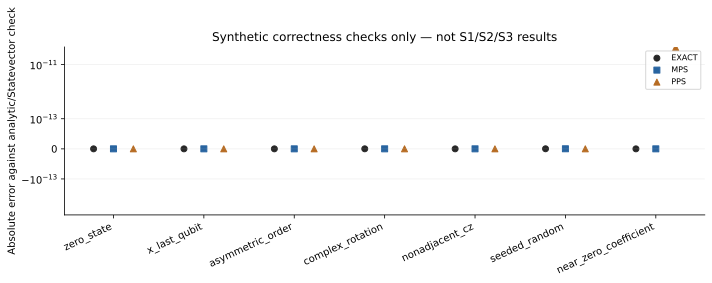

,checks,max_abs_error,all_passed
method,,,
exact,7,2.220446e-16,True
mps,7,1.665335e-16,True
pps,7,4.265710e-11,True


In [5]:
import matplotlib.pyplot as plt
if not checks.empty:
    figure = plot_checks(checks, OUTPUT_ROOT / "synthetic_checks" / "figures")
    display(figure)
    plt.close(figure)
    display(checks.groupby("method", sort=False).agg(
        checks=("passed", "size"), max_abs_error=("abs_error", "max"), all_passed=("passed", "all")))

## Small Synthetic Pipeline Check

Exercise the experiment, plotting, caching, and export path on **one four-qubit
synthetic circuit**, separate from all official samples. Scan `chi = 1, 2, 4`
and `eta = 0.01, 0.001`, giving six tasks including the exact reference.
The second pass must reuse all six successful cache entries. The generated
CSV tables and their hashes are read back; no official submission is exported.

,sample,method,setting,paired_ids,mae,wall_seconds
0,SYNTHETIC_CHECKS,exact,double,1,0.000000e+00,5.759826
1,SYNTHETIC_CHECKS,mps,chi=1,1,4.546906e-01,5.510986
2,SYNTHETIC_CHECKS,mps,chi=2,1,1.515633e-01,5.297414
3,SYNTHETIC_CHECKS,mps,chi=4,1,3.885781e-16,4.557818
4,SYNTHETIC_CHECKS,pps,eta=0.01,1,1.110223e-16,4.770970
5,SYNTHETIC_CHECKS,pps,eta=0.001,1,1.110223e-16,4.586812


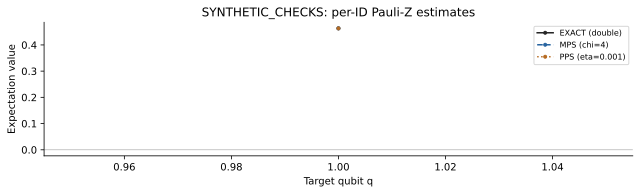

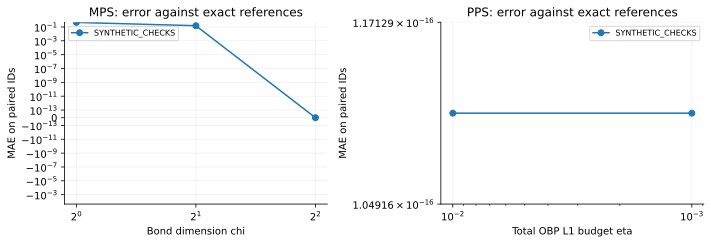

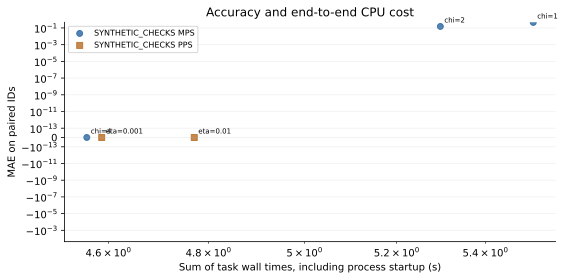

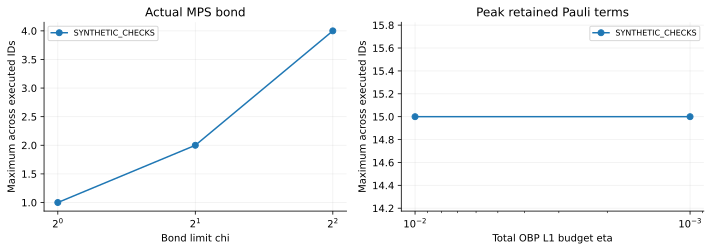

{'status': 'VERIFIED', 'files': 10}

**Small pipeline:** six tasks succeeded; cache resume and CSV/hash read-back passed. All figures in this section describe synthetic data only.

In [6]:
from bluequbit_samples.checks import synthetic_cases
from bluequbit_samples.plots import plot_predictions, plot_convergence, plot_cost_error, plot_diagnostics

small_records = []
small_cache_verified = False
if RUN_SMALL_PIPELINE:
    small_sample = next(sample for name, sample, _ in synthetic_cases() if name == "seeded_random")
    assert small_sample.dataset_kind == "synthetic" and small_sample.num_qubits <= 4
    small_root = OUTPUT_ROOT / "small_pipeline"
    small_records = run_suite([small_sample], small_root, config,
                              chis=(1, 2, 4), etas=(1e-2, 1e-3), progress=False)
    if not all(record.succeeded for record in small_records):
        raise RuntimeError("The small synthetic pipeline failed; inspect its task records.")
    resumed = run_suite([small_sample], small_root, config,
                        chis=(1, 2, 4), etas=(1e-2, 1e-3), progress=False)
    small_cache_verified = len(resumed) == 6 and all(record.cache_hit for record in resumed)
    assert small_cache_verified, "Successful synthetic tasks were not resumed from cache"
    small_summary = summary_table([small_sample], small_records)
    display(small_summary[["sample", "method", "setting", "paired_ids", "mae", "wall_seconds"]])
    small_figures = small_root / "exports" / "figures"
    for figure in (
        plot_predictions(small_records, small_figures),
        plot_convergence(small_summary, small_figures),
        plot_cost_error(small_summary, small_figures),
        plot_diagnostics(small_records, small_figures),
    ):
        if figure is not None:
            display(figure)
            plt.close(figure)
    small_export = export_results([small_sample], small_records, small_root / "exports")
    assert all(item["status"] == "NO_OFFICIAL_INPUTS" for item in small_export["submissions"].values())
    display(verify_exports(small_root / "exports"))
    display(Markdown("**Small pipeline:** six tasks succeeded; cache resume and CSV/hash read-back passed. "
                     "All figures in this section describe synthetic data only."))

## Step 1: Exact Numerical References

Aer uses a noiseless, double-precision `statevector` simulation and saves the
target expectation directly, without shots or a dense $2^n\times2^n$ unitary.
The state alone occupies $16\,2^n$ bytes. The preflight guard budgets three
state arrays plus 192 MiB of runtime overhead; a process monitor also measures
actual RSS and enforces the worker cap.

For $n\le10$, Qiskit `Statevector` independently checks the expectation and state
normalization. Other successful Aer references are labeled `EXACT_COMPUTED`,
not silently promoted to `EXACT_CROSSCHECKED`. Resource failures remain missing.

In [7]:
exact_records = []
if OFFICIAL_READY:
    exact_records = run_suite(samples, OUTPUT_ROOT / "exact", config, methods=("exact",))
    exact_table = records_frame(exact_records)
    display(exact_table[["circuit_id", "estimate", "status", "reference_status", "wall_seconds", "peak_rss"]])
else:
    display(Markdown("**Official exact references: NOT RUN in this notebook execution.** "
                     "Official execution is disabled, or the input manifest is incomplete."))

**Official exact references: NOT RUN in this notebook execution.** Official execution is disabled, or the input manifest is incomplete.

## Step 2: MPS Bond-Dimension Sweep

`quimb.CircuitMPS` applies the original gates in order. Nonlocal gates use explicit
`swap+split` routing, restoring original site order. The additional SVD cutoff
is fixed at 0, so the requested bond cap $\chi$ controls the approximation.

$$\hat F_\chi=\frac{\langle\psi_\chi|Z_q|\psi_\chi\rangle}
{\langle\psi_\chi|\psi_\chi\rangle},\qquad
\chi\in\{16,32,64,128,256\}.$$

The denominator matters: a truncated MPS need not have unit norm. Save its norm
and actual maximum bond. Smaller errors at every successive bond are not assumed.

In [8]:
mps_records = []
if OFFICIAL_READY:
    mps_records = run_suite(samples, OUTPUT_ROOT / "mps", config, methods=("mps",), chis=CHIS)
    display(records_frame(mps_records)[["circuit_id", "setting", "estimate", "status", "max_bond_actual", "state_norm_squared"]].head(15))
else:
    display(Markdown("**Official MPS sweep: NOT RUN.** Set RUN_OFFICIAL to True only when a full sample run is intended."))

**Official MPS sweep: NOT RUN.** Set RUN_OFFICIAL to True only when a full sample run is intended.

## Step 3: Pauli Backpropagation Sweep

OBP propagates $Z_q$ backwards through one-gate slices. For the resulting operator
$U^\dagger Z_qU=\sum_P a_P P$, the all-zero expectation is

$$\hat F=\sum_{P\in\{I,Z\}^{\otimes n}}a_P.$$

Use total $L_1$ truncation-error budgets
$\eta\in\{10^{-2},10^{-3},10^{-4},10^{-5}\}$, distributed across slices.
This **is not** BlueQubit's per-coefficient threshold. Library simplification
and gate-decomposition tolerances are recorded separately.

The Pauli count is capped. If OBP leaves any unpropagated prefix, the record is
`INCOMPLETE` with no accepted estimate. Only complete propagation allows the
diagonal-Pauli sum above. Windows timeouts are enforced by the parent process.

In [9]:
pps_records = []
if OFFICIAL_READY:
    pps_records = run_suite(samples, OUTPUT_ROOT / "pps", config, methods=("pps",), etas=ETAS)
    display(records_frame(pps_records)[["circuit_id", "setting", "estimate", "status", "peak_num_paulis", "remaining_slices"]].head(15))
else:
    display(Markdown("**Official PPS sweep: NOT RUN.** Set RUN_OFFICIAL to True only when a full sample run is intended."))

**Official PPS sweep: NOT RUN.** Set RUN_OFFICIAL to True only when a full sample run is intended.

## Results: Accuracy, Coverage, and CPU Cost

Errors are calculated only on IDs with successful exact references. Each summary
shows expected IDs, completed IDs, and paired IDs. MAE/RMSE over a subset are
subset metrics. Whole-problem correlation and score require a full matched vector.

$$\mathrm{score}_c=100[\max(0,\rho_c)]^2,$$

where $\rho_c$ is Pearson correlation within sample $c$. Constant predictions
score 0; a constant reference is flagged because Pearson is undefined. The local
near-constant tolerance is not claimed to be the official threshold.

Wall time includes child-process startup. `compute_seconds` is also retained.
RSS is a process-tree peak, not GPU memory. Cache hits reuse the original measured
runtime rather than presenting cache retrieval as a simulation speedup.

In [10]:
records = exact_records + mps_records + pps_records
comparison = comparison_table(records)
summary = summary_table(samples, records)
if records:
    display(summary)
    display(comparison[["circuit_id", "method", "setting", "estimate", "reference", "absolute_error", "status"]].head(18))
else:
    display(Markdown("**Official results unavailable:** the three computational stages have not run. "
                     "Synthetic check results above remain separately labeled."))

**Official results unavailable:** the three computational stages have not run. Synthetic check results above remain separately labeled.

In [11]:
from bluequbit_samples.plots import plot_predictions, plot_convergence, plot_cost_error, plot_diagnostics

FIGURE_DIR = OUTPUT_ROOT / "exports" / "figures"
if records:
    figure = plot_predictions(records, FIGURE_DIR)
    if figure is not None:
        display(figure)
        plt.close(figure)

In [12]:
if records:
    figure = plot_convergence(summary, FIGURE_DIR)
    if figure is not None:
        display(figure)
        plt.close(figure)

In [13]:
if records:
    figure = plot_cost_error(summary, FIGURE_DIR)
    if figure is not None:
        display(figure)
        plt.close(figure)

In [14]:
if records:
    figure = plot_diagnostics(records, FIGURE_DIR)
    if figure is not None:
        display(figure)
        plt.close(figure)

## Export and Read-Back Verification

Save original records, input identities, exact references, scan details, metrics,
and figures. Export one `circuit_id,value` CSV per sample only when every ID has
a matching successful exact reference. Synthetic data and partial references are
never substituted. Values are written with 17 significant digits and read back.

SHA-256 manifests verify exported files after transfer. Exported files are **not
uploaded or submitted** by this notebook; include a truthful method note when
using the competition's submission interface.

In [15]:
export_receipt = None
if records:
    export_receipt = export_results(samples, records, OUTPUT_ROOT / "exports")
    display(pd.DataFrame(export_receipt["submissions"]).T)
    display(verify_exports(OUTPUT_ROOT / "exports"))
else:
    display(Markdown("**Official submission files: NOT EXPORTED by this notebook execution.** "
                     "The small synthetic pipeline cannot produce official submission CSVs."))

**Official submission files: NOT EXPORTED by this notebook execution.** The small synthetic pipeline cannot produce official submission CSVs.

## Running the current workflow

Use `scripts/run_workflow.py` for calibration and `scripts/graded_workflow.py` for hidden-ID planning. Read `workflow_final.md` before cloud execution. This notebook is exploratory: its OBP total-L1 budget (`eta`) is distinct from the final coefficient-cutoff Pauli engine (`epsilon`). All calls to the local execution wrapper enter `runs/`; no external compute service is configured by this notebook.


## Takeaways and Completion Status

The following summary is computed from executed records. Successful synthetic
checks do not mean that the actual S1/S2/S3 answers have been computed.

In [16]:
expected_tasks = len(samples) * (1 + len(CHIS) + len(ETAS))
official_complete = bool(OFFICIAL_READY and records and len(records) == expected_tasks
                         and all(record.succeeded for record in records))
state = ("COMPLETE_COMPUTED" if official_complete else "PARTIAL" if records
         else "NOT_RUN_DISABLED" if not RUN_OFFICIAL else "NOT_RUN_MISSING_INPUTS")
validation_summary = {
    "official_state": state,
    "official_input_ids": len(samples),
    "expected_official_input_ids": config.expected_total,
    "official_tasks_run": len(records),
    "official_tasks_succeeded": sum(record.succeeded for record in records),
    "exact_references_computed": sum(record.succeeded for record in exact_records),
    "exact_references_crosschecked": sum(record.diagnostics.get("reference_status") == "EXACT_CROSSCHECKED"
                                          for record in exact_records),
    "synthetic_checks_run": len(checks),
    "synthetic_checks_passed": int(checks.passed.sum()) if not checks.empty else 0,
    "small_pipeline_tasks_succeeded": sum(record.succeeded for record in small_records),
    "small_pipeline_cache_verified": small_cache_verified,
    "remote_validation": "SKIPPED_BY_REQUEST",
    "submitted_to_platform": False,
}
atomic_json(OUTPUT_ROOT / "notebook_status.json", validation_summary)
display(pd.DataFrame(validation_summary.items(), columns=["Item", "Observed status / count"]))
if not official_complete:
    display(Markdown("This delivery validates **small circuits only**. Official sample sweeps are disabled "
                     "by default, and NRP/Expanse checks are skipped. Do not infer sample answers from synthetic checks."))

,Item,Observed status / count
0,official_state,NOT_RUN_DISABLED
1,official_input_ids,50
2,expected_official_input_ids,50
3,official_tasks_run,0
4,official_tasks_succeeded,0
5,exact_references_computed,0
6,exact_references_crosschecked,0
7,synthetic_checks_run,21
8,synthetic_checks_passed,21
9,small_pipeline_tasks_succeeded,6


This delivery validates **small circuits only**. Official sample sweeps are disabled by default, and NRP/Expanse checks are skipped. Do not infer sample answers from synthetic checks.

## Sources

- [Official BlueQubit challenge](https://app.bluequbit.io/hackathons/2GMaAenu3iSsIC6Z)
  and [Rules](https://app.bluequbit.io/hackathons/2GMaAenu3iSsIC6Z?tab=rules).
- [Qiskit Aer simulator options](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html).
- [quimb circuit MPS](https://quimb.readthedocs.io/en/latest/circuit/circuit-mps.html).
- [Classical simulation with OBP](https://qiskit.github.io/qiskit-addon-obp/how_tos/simulating_circuits_with_obp.html)
  and [OBP truncation budgets](https://qiskit.github.io/qiskit-addon-obp/how_tos/truncate_operator_terms.html).

Scope: public S1/S2/S3 only. Hidden circuits, estimator fusion, extrapolation,
and adaptive credit scheduling are outside this notebook's implementation.